# JS07: Tugas Lab

Klasterisasi data nasabah kartu kredit.

## Persiapan dataset

In [1]:
from pathlib import Path
from urllib.request import Request, urlopen

data_path = Path('CC_Customer_Dataset.csv')
if not data_path.exists():
    request = Request('https://1812311909-files.gitbook.io/~/files/v0/b/gitbook-x-prod.appspot.com/o/spaces%2FYHOv2XH8FJMJSMsnhwNa%2Fuploads%2FtUHTofsaCAu01AQLD2W1%2FCC_Customer_Dataset.csv?alt=media&token=f41e58d9-7c29-4e26-8e16-f93bf44c0556', headers={'User-Agent': 'Mozilla/5.0'})
    with urlopen(request, timeout=120) as response:
        data_path.write_bytes(response.read())
print(f'Dataset siap: {data_path.name}')

Dataset siap: CC_Customer_Dataset.csv


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score

df = pd.read_csv(data_path)
print('Ukuran data:', df.shape)
print('Jumlah nilai kosong:', df.isna().sum().sum())
df.head()

Ukuran data: (660, 7)
Jumlah nilai kosong: 0


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


## Soal 1: Scatterplot dua variabel

Kolom yang disebut Total_credit_card dalam soal bernama Total_Credit_Cards pada dataset.

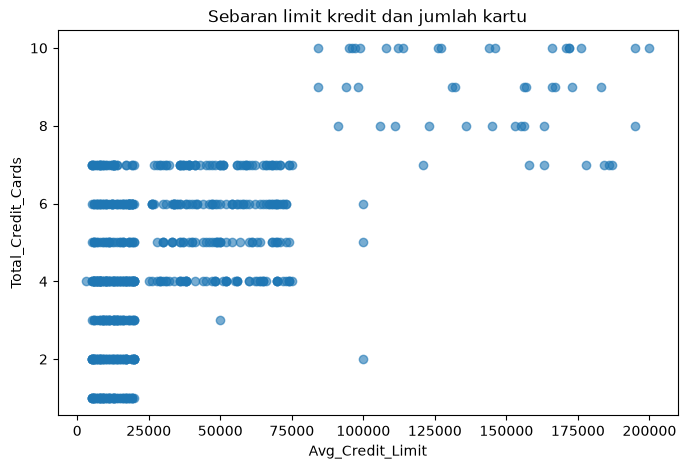

In [3]:
plt.figure(figsize=(8, 5))
plt.scatter(df['Avg_Credit_Limit'], df['Total_Credit_Cards'], alpha=0.6)
plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.title('Sebaran limit kredit dan jumlah kartu')
plt.show()

Sebaran tidak mengikuti satu garis lurus. Limit kredit yang lebih tinggi cenderung disertai jumlah kartu lebih banyak, tetapi titiknya menyebar dan saling tumpang tindih. Scatterplot dua variabel ini belum cukup untuk menyimpulkan keterpisahan semua klaster.

## Soal 2: K Means dan elbow method

Model menggunakan lima fitur: Avg_Credit_Limit, Total_Credit_Cards, Total_visits_bank, Total_visits_online, dan Total_calls_made. Sl_No serta Customer Key dikeluarkan karena merupakan identitas. Standardisasi menyetarakan skala limit kredit dengan jumlah kartu dan aktivitas nasabah.

 k         SSE
 1 3300.000000
 2 2040.989816
 3  933.043749
 4  780.773690
 5  704.475919
 6  642.273712
 7  599.925397
 8  567.327773
 9  542.253247
10  516.242046


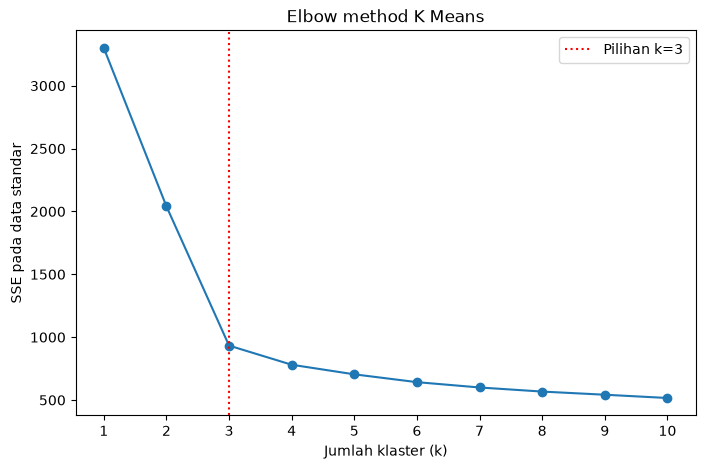

In [4]:
features = df.drop(columns=['Sl_No', 'Customer Key'])
scaler = StandardScaler()
X = scaler.fit_transform(features)
K = range(1, 11)
sse = []

for k in K:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X)
    sse.append(model.inertia_)

elbow_results = pd.DataFrame({'k': list(K), 'SSE': sse})
print(elbow_results.to_string(index=False, float_format=lambda value: f'{value:.6f}'))
plt.figure(figsize=(8, 5))
plt.plot(K, sse, marker='o')
plt.axvline(3, linestyle=':', color='red', label='Pilihan k=3')
plt.xticks(list(K))
plt.xlabel('Jumlah klaster (k)')
plt.ylabel('SSE pada data standar')
plt.title('Elbow method K Means')
plt.legend()
plt.show()

Saya memilih k=3. SSE turun dari sekitar 2040,99 pada k=2 menjadi 933,04 pada k=3. Pada k=4, SSE hanya turun menjadi 780,77. Perubahan penurunan yang tajam ini membentuk siku pada k=3.

## Soal 3: Scatterplot hasil K Means

Warna berasal dari model lima fitur. Scatterplot menampilkan proyeksinya pada dua variabel yang diminta.

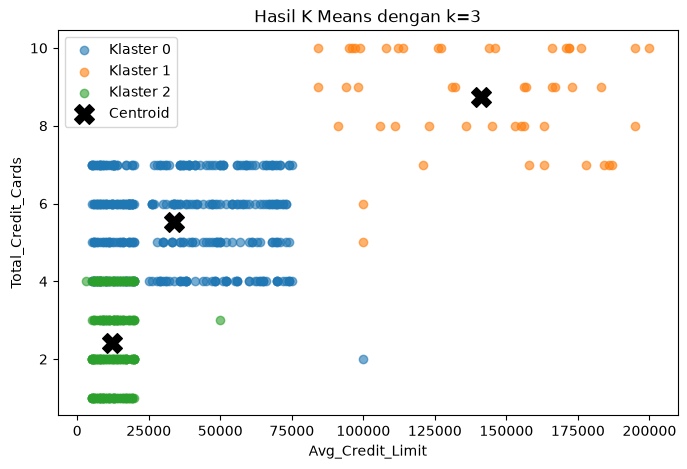

SSE model terpilih: 933.0437490000536
Jumlah anggota K Means:
0    386
1     50
2    224
Name: count, dtype: int64


In [5]:
best_k = 3
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X)
centers = scaler.inverse_transform(kmeans.cluster_centers_)
plt.figure(figsize=(8, 5))
for label in sorted(np.unique(kmeans_labels)):
    mask = kmeans_labels == label
    plt.scatter(df.loc[mask, 'Avg_Credit_Limit'], df.loc[mask, 'Total_Credit_Cards'],
                alpha=0.6, label=f'Klaster {label}')
plt.scatter(centers[:, 0], centers[:, 1], marker='X', s=200, c='black', label='Centroid')
plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.title('Hasil K Means dengan k=3')
plt.legend()
plt.show()
print('SSE model terpilih:', kmeans.inertia_)
print('Jumlah anggota K Means:')
print(pd.Series(kmeans_labels).value_counts().sort_index())

## Soal 4: Model DBSCAN dengan seluruh fitur yang relevan

DBSCAN memakai lima fitur standar yang sama. Identitas nasabah tidak ikut dihitung. Pemilihan eps dijelaskan pada soal 5 sebelum model dilatih.

In [6]:
min_samples = 5
neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors.fit(X)
distances, _ = neighbors.kneighbors(X)
neighbor_distances = np.sort(distances[:, -1])

## Soal 5: Elbow method dan pemilihan parameter

Jumlah k pada K Means sudah dipilih sebagai 3 di soal 2. DBSCAN tidak memakai k sebagai jumlah klaster. Untuk DBSCAN, grafik siku jarak tetangga digunakan untuk memilih eps, sedangkan jumlah klaster terbentuk dari kepadatan data. Dengan min_samples=5, jarak yang ditampilkan adalah jarak tetangga kelima termasuk titik itu sendiri.

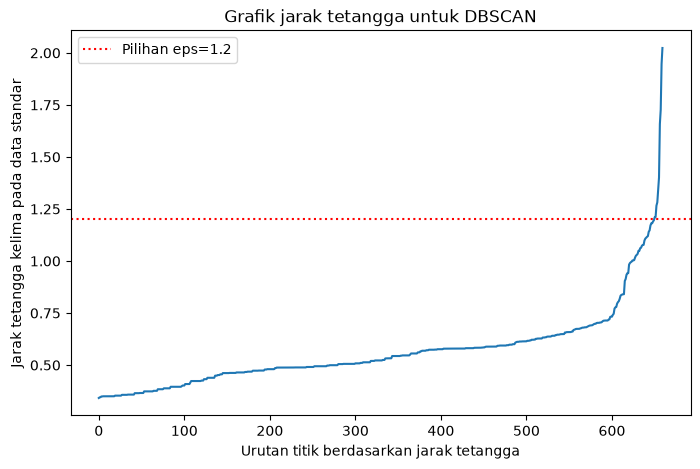

 eps  Jumlah klaster  Jumlah noise
 0.7               1            58
 0.9               3            27
 1.2               2             4
 1.5               2             1


In [7]:
eps = 1.2
plt.figure(figsize=(8, 5))
plt.plot(neighbor_distances)
plt.axhline(eps, color='red', linestyle=':', label=f'Pilihan eps={eps}')
plt.xlabel('Urutan titik berdasarkan jarak tetangga')
plt.ylabel('Jarak tetangga kelima pada data standar')
plt.title('Grafik jarak tetangga untuk DBSCAN')
plt.legend()
plt.show()

eps_results = []
for candidate in [0.7, 0.9, 1.2, 1.5]:
    candidate_labels = DBSCAN(eps=candidate, min_samples=min_samples).fit_predict(X)
    eps_results.append({
        'eps': candidate,
        'Jumlah klaster': len(set(candidate_labels) - {-1}),
        'Jumlah noise': np.sum(candidate_labels == -1),
    })
print(pd.DataFrame(eps_results).to_string(index=False))

Grafik memiliki beberapa perubahan kemiringan pada bagian akhirnya. Saya memilih eps=1,2 untuk mencakup daerah yang lebih jarang sebelum kenaikan jarak terbesar di ujung grafik. Pada eps=0,7, model menghasilkan satu klaster dan 58 noise. Pada eps=1,2, terbentuk dua klaster dan empat noise. Menaikkan eps menjadi 1,5 tetap menghasilkan dua klaster, tetapi mengurangi noise menjadi satu. Pilihan eps=1,2 mempertahankan lebih banyak titik yang terisolasi sebagai noise. Nilai ini dipilih untuk percobaan ini, bukan jaminan parameter terbaik untuk semua kebutuhan.

Parameter DBSCAN: {'algorithm': 'auto', 'eps': 1.2, 'leaf_size': 30, 'metric': 'euclidean', 'metric_params': None, 'min_samples': 5, 'n_jobs': None, 'p': None}
Jumlah klaster DBSCAN: 2
Jumlah noise: 4
Persentase noise: 0.606061%
Jumlah anggota DBSCAN:
-1      4
 0    608
 1     48
Name: count, dtype: int64


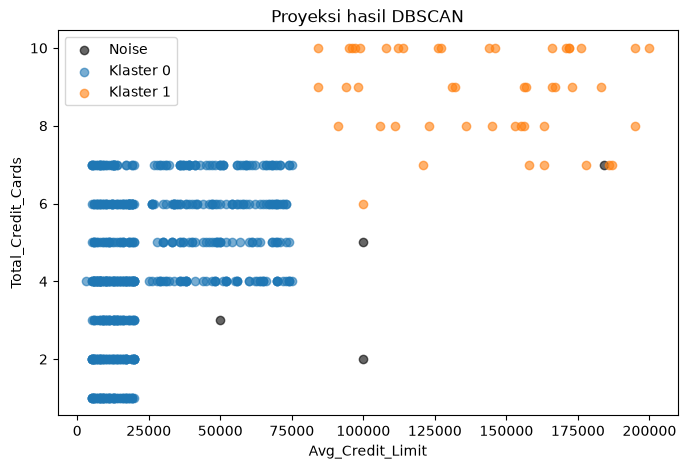

In [8]:
dbscan = DBSCAN(eps=eps, min_samples=min_samples)
dbscan_labels = dbscan.fit_predict(X)
n_clusters = len(set(dbscan_labels) - {-1})
n_noise = np.sum(dbscan_labels == -1)
print('Parameter DBSCAN:', dbscan.get_params())
print('Jumlah klaster DBSCAN:', n_clusters)
print('Jumlah noise:', n_noise)
print(f'Persentase noise: {n_noise / len(X) * 100:.6f}%')
print('Jumlah anggota DBSCAN:')
print(pd.Series(dbscan_labels).value_counts().sort_index())

plt.figure(figsize=(8, 5))
for label in sorted(np.unique(dbscan_labels)):
    mask = dbscan_labels == label
    name = 'Noise' if label == -1 else f'Klaster {label}'
    color = 'black' if label == -1 else None
    plt.scatter(df.loc[mask, 'Avg_Credit_Limit'], df.loc[mask, 'Total_Credit_Cards'],
                label=name, color=color, alpha=0.6)
plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.title('Proyeksi hasil DBSCAN')
plt.legend()
plt.show()

## Soal 6: Silhouette score dan DBI

Evaluasi utama mengecualikan noise berlabel negatif satu karena noise bukan satu klaster. Sebagai pembanding, metrik seluruh data juga ditampilkan dengan noise diperlakukan sebagai satu kelompok.

In [9]:
valid = dbscan_labels != -1
metric_results = []
for name, metric_X, metric_labels in [
    ('Tanpa noise', X[valid], dbscan_labels[valid]),
    ('Termasuk noise', X, dbscan_labels),
]:
    if 2 <= len(np.unique(metric_labels)) < len(metric_labels):
        metric_results.append({
            'Evaluasi': name,
            'Jumlah data': len(metric_labels),
            'Silhouette': silhouette_score(metric_X, metric_labels),
            'DBI': davies_bouldin_score(metric_X, metric_labels),
        })
    else:
        print(f'{name}: metrik memerlukan sedikitnya dua klaster.')

metric_results = pd.DataFrame(metric_results)
print(metric_results.to_string(index=False, float_format=lambda value: f'{value:.6f}'))

      Evaluasi  Jumlah data  Silhouette      DBI
   Tanpa noise          656    0.572307 0.628783
Termasuk noise          660    0.477034 1.440617


## Analisis hasil

K Means membentuk tiga klaster pada lima fitur nasabah. DBSCAN membentuk dua klaster dan menandai empat nasabah sebagai noise. Hasilnya berbeda karena K Means memakai jarak ke centroid, sedangkan DBSCAN menghubungkan daerah yang cukup padat. Nilai silhouette dan DBI perlu dilihat bersama jumlah anggota serta noise, terutama karena ukuran klaster DBSCAN tidak seimbang.